In [1]:
import xformers.ops as xops

In [2]:
bdcm = xops.fmha.attn_bias.BlockDiagonalCausalMask.from_seqlens(q_seqlen=[2, 4, 3], kv_seqlen=[5, 5, 5])

In [3]:
bdmaks_br = bdcm.make_causal_from_bottomright().materialize([1, 1, 9, 15])

In [4]:
bdmaks_normal = bdcm.materialize([1, 1, 9, 15])

In [5]:
bdmaks = bdmaks_br

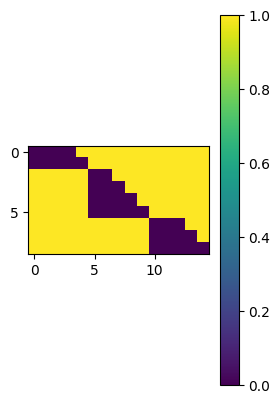

In [6]:
bdmaks_np = bdmaks.numpy()

bdmaks_np = bdmaks_np.reshape(9, 15)

# replace -inf with 1
bdmaks_np[bdmaks_np == -float("inf")] = 1

# make a heat map
import matplotlib.pyplot as plt
import numpy as np

plt.subplot(1, 2, 1)

plt.imshow(bdmaks_np)
# add a color bar
plt.colorbar()
plt.show()


2
5
4
5
3
5


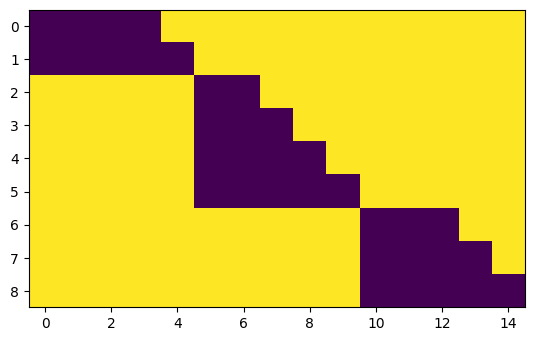

In [19]:
def make_block_causal_mask(q_seqlen, kv_seqlen):
    q_len = sum(q_seqlen)
    kv_len = sum(kv_seqlen)

    mask = np.zeros((q_len, kv_len), dtype=np.float32) + 1

    q_start = 0
    kv_start = 0

    for q_l, kv_l in zip(q_seqlen, kv_seqlen):

      print(q_l)
      print(kv_l)

      cache_end = kv_l - q_l

      for i in range(q_l):
        mask[q_start:q_start + q_l, kv_start:kv_start + cache_end] = 0
        
        for j in range(kv_l):
          if j <= i:
            mask[q_start + i, kv_start  + cache_end + j] = 0

      q_start += q_l
      kv_start += kv_l      


    return mask

test_mask = make_block_causal_mask([2, 4, 3], [5, 5, 5])
# plot the mask
plt.imshow(test_mask)
plt.show()

In [ ]:
cached
[ana are mere si vrea] sa faca



[ana are pad pad pad][george ]